# Deep Hedging with Transaction Costs

Black–Scholes says an option can be hedged perfectly by trading continuously. Real trading is discrete and every trade costs money, so a dealer has to decide how much risk each trade is worth. Deep hedging lets a neural network learn that decision by minimising the losses in the bad scenarios directly. This notebook trains one and compares it with the textbook hedges.

**What it does.** It trains a neural network to hedge a short one-month SPY call with daily trading and proportional transaction costs, minimising tail risk (CVaR) instead of replicating Black–Scholes.

It is compared with no hedge, the Black–Scholes delta and the Whalley–Wilmott no-trade band, under Black–Scholes and Heston dynamics.

**Data.** SPY daily prices (Yahoo Finance) set the volatility, the Heston variant uses illustrative parameters consistent with SPY, and Treasury yields (FRED) give the rate.

**Methods.** Deep Hedging (Buehler, Gonon, Teichmann & Wood, 2019) with a recurrent policy (the previous position is an input) in PyTorch, trained on 200,000 simulated paths to minimise the CVaR₉₅ of the hedged loss.

The strategies are evaluated out of sample on fresh paths, and the CVaR-optimal value is read as an indifference price.

**Key output.** P&L distributions, CVaR and turnover by strategy and cost level, the learned hedge ratio showing a data-driven no-trade band, and the price a seller should charge to cover costs and tail risk.

## 1. Why delta hedging is not enough

Black–Scholes says a call can be replicated perfectly by continuously holding Δ shares. Reality breaks every assumption: trading is discrete, it costs money, and volatility is not constant. A dealer, or an MDB hedging an option embedded in a structured note, then has to decide **how much to trade** given that each trade costs money but reduces risk.

**Deep hedging** turns this into an optimisation problem. With hedge positions $\delta_t$ from a policy network,

$$
\text{Loss} = \underbrace{(S_T-K)^+}_{\text{option sold}}-\sum_{t}\delta_t\,(S_{t+1}-S_t)+\underbrace{\varepsilon\sum_t |\delta_t-\delta_{t-1}|\,S_t}_{\text{transaction costs}},
\qquad \min_{\text{policy}}\ \mathrm{CVaR}_{95\%}(\text{Loss}).
$$

The optimal CVaR is the amount of cash the seller needs today to make the position acceptable: an **indifference price** that includes costs and tail risk. Feeding the previous position $\delta_{t-1}$ into the network lets it learn **not to trade** when the gain in risk is smaller than the cost, which is what the classical Whalley–Wilmott band does analytically.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import torch

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import yfinance as yf
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

N_DAYS = 21  # one-month option, daily rebalancing
K_REL = 1.0  # ATM
# proportional transaction cost (fraction of traded value)
COSTS = [0.0, 0.0005, 0.002, 0.005]
N_TRAIN, N_TEST = 200_000, 100_000
ALPHA = 0.95  # CVaR level
SEED = 31
torch.manual_seed(SEED)
torch.set_num_threads(max(1, (os.cpu_count() or 4) // 2))

print(
    f"torch {torch.__version__} · yfinance {yf.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

torch 2.14.1+cu130 · yfinance 1.7.0 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


STRAT_COLORS = {
    "No hedge": "#c9c8c3",
    "BS delta": PALETTE[0],
    "Whalley–Wilmott band": PALETTE[2],
    "Deep hedge": PALETTE[1],
}

## 3. Market calibration

In [3]:
def fetch_spy():
    px = yf.download("SPY", period="3y", auto_adjust=True, progress=False)[
        "Close"
    ]
    px = px.iloc[:, 0] if isinstance(px, pd.DataFrame) else px
    px.index = pd.to_datetime(px.index).tz_localize(None)
    return px.rename("SPY").to_frame()


spy = cached("yahoo_spy_3y", fetch_spy)["SPY"]
spy = spy[spy.index < pd.Timestamp.today().normalize()]
ret = np.log(spy).diff().dropna()
SIGMA = float(ret[-252:].std() * np.sqrt(252))
R = float(np.log(1 + fred.get_series("DGS1MO").dropna().iloc[-1] / 100))
T = N_DAYS / 252
DT = 1 / 252
# Heston variant: long-run variance matched to SPY's realised variance; mean
# reversion, vol-of-vol and correlation are illustrative values typical of
# index calibrations to the option smile.
HESTON = dict(v0=SIGMA**2, kappa=3.0, theta=SIGMA**2, xi=0.6, rho=-0.7)
print(
    f"SPY 1y realised vol {SIGMA:.1%} · 1M rate {R:.2%} · option"
    f" {N_DAYS} trading days, ATM · Heston "
    + ", ".join(f"{k}={v:.3g}" for k, v in HESTON.items())
)


def simulate(n, model, seed):
    rng = np.random.default_rng(seed)
    S = np.ones((n, N_DAYS + 1))
    V = np.full((n, N_DAYS + 1), SIGMA**2)
    for t in range(N_DAYS):
        z1 = rng.standard_normal(n)
        if model == "Black–Scholes":
            S[:, t + 1] = S[:, t] * np.exp(
                (R - 0.5 * SIGMA**2) * DT + SIGMA * np.sqrt(DT) * z1
            )
        else:
            z2 = HESTON["rho"] * z1 + np.sqrt(
                1 - HESTON["rho"] ** 2
            ) * rng.standard_normal(n)
            v = np.maximum(V[:, t], 0)
            S[:, t + 1] = S[:, t] * np.exp(
                (R - 0.5 * v) * DT + np.sqrt(v * DT) * z1
            )
            V[:, t + 1] = np.maximum(
                v
                + HESTON["kappa"] * (HESTON["theta"] - v) * DT
                + HESTON["xi"] * np.sqrt(v * DT) * z2,
                0,
            )
    return S, V


def bs_call(S, K, tau, sig, r):
    tau = np.maximum(tau, 1e-10)
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * tau) / (sig * np.sqrt(tau))
    return S * stats.norm.cdf(d1) - K * np.exp(-r * tau) * stats.norm.cdf(
        d1 - sig * np.sqrt(tau)
    )


def bs_delta_gamma(S, K, tau, sig, r):
    tau = np.maximum(tau, 1e-10)
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * tau) / (sig * np.sqrt(tau))
    return stats.norm.cdf(d1), stats.norm.pdf(d1) / (S * sig * np.sqrt(tau))


BS_PRICE = float(bs_call(1.0, K_REL, T, SIGMA, R))
print(f"Black–Scholes premium of the ATM call: {BS_PRICE * 100:.3f}% of spot")

SPY 1y realised vol 12.7% · 1M rate 4.09% · option 21 trading days, ATM · Heston v0=0.0162, kappa=3, theta=0.0162, xi=0.6, rho=-0.7
Black–Scholes premium of the ATM call: 1.638% of spot


## 4. Benchmark strategies

- **No hedge:** keep the premium and pay the option at expiry.
- **Black–Scholes delta:** rebalance to $\Delta_{BS}$ every day, paying costs on every trade.

**Whalley–Wilmott band:** trade only when the position leaves a band around $\Delta_{BS}$ of half-width $H=\big(\tfrac32\,e^{-r\tau}\,\varepsilon\,S\,\Gamma^2/\lambda\big)^{1/3}$, and then only back to the edge of the band. It is the asymptotically optimal policy for small costs under exponential utility with risk aversion $\lambda$. Because $\lambda$ has units (one over wealth) and the notional here is one share, $\lambda$ is **tuned on separate training paths** to minimise CVaR95 at each cost level, the same objective the deep hedge is trained on. That makes the comparison fair.

All strategies are self-financing from the premium (BS price) and are judged by the distribution of the **hedged loss** (positive = loss).

In [4]:
def run_strategy(S, cost, policy, V=None, ww_lambda=1.0):
    n = S.shape[0]
    pos = np.zeros(n)
    pnl = np.full(n, BS_PRICE)  # premium received
    turnover = np.zeros(n)
    for t in range(N_DAYS):
        tau = T - t * DT
        if policy == "No hedge":
            new = np.zeros(n)
        else:
            sig_t = SIGMA if V is None else np.sqrt(np.maximum(V[:, t], 1e-8))
            delta, gamma = bs_delta_gamma(S[:, t], K_REL, tau, sig_t, R)
            if policy == "BS delta":
                new = delta
            else:
                H = (
                    1.5
                    * np.exp(-R * tau)
                    * max(cost, 1e-12)
                    * S[:, t]
                    * gamma**2
                    / ww_lambda
                ) ** (1 / 3)
                new = np.clip(pos, delta - H, delta + H)
        trade = new - pos
        pnl -= cost * np.abs(trade) * S[:, t]
        turnover += np.abs(trade)
        pos = new
        # hedge gain in excess of financing at r
        pnl += pos * (S[:, t + 1] - S[:, t] * np.exp(R * DT))
        # (interest on the premium is ignored: over one month it is worth <
        # 0.01% of spot)
    pnl -= np.maximum(S[:, -1] - K_REL, 0)
    return -pnl, turnover  # loss, turnover


def cvar(loss, a=ALPHA):
    q = np.quantile(loss, a)
    return loss[loss >= q].mean()

## 5. The deep hedging policy

The network maps today's features to tomorrow's position: $\ln(S_t/K)$, time to maturity, the previous position $\delta_{t-1}$, and the Black–Scholes delta as a hint. It is the same network at every date (time is an input), with 3 layers of 64 units. The CVaR is optimised with the Rockafellar–Uryasev representation, $\mathrm{CVaR}_\alpha(L)=\min_w\, w+\frac{1}{1-\alpha}\mathbb E[(L-w)^+]$, so $w$ (the VaR) is learned jointly with the policy.

Under Heston, the instantaneous variance $v_t$ is also an input to the network and to the delta benchmarks, which is the setting where a model-free policy can add the most.

In [5]:
class HedgePolicy(torch.nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.net = torch.nn.Sequential(
            torch.nn.Linear(n_in, 64),
            torch.nn.SiLU(),
            torch.nn.Linear(64, 64),
            torch.nn.SiLU(),
            torch.nn.Linear(64, 64),
            torch.nn.SiLU(),
            torch.nn.Linear(64, 1),
        )
        # VaR level in the Rockafellar–Uryasev objective
        self.w = torch.nn.Parameter(torch.tensor(0.01))

    def forward(self, x):
        return self.net(x).squeeze(-1)


def deep_hedge_loss(policy, S, V, cost, use_var):
    """
    Simulate the hedge along all paths (tensors) and return the per-path loss
    and turnover.
    """
    n = S.shape[0]
    pos = torch.zeros(n)
    pnl = torch.full((n,), BS_PRICE)
    turnover = torch.zeros(n)
    for t in range(N_DAYS):
        tau = T - t * DT
        sig_t = (
            torch.sqrt(torch.clamp(V[:, t], min=1e-8))
            if use_var
            else torch.full((n,), SIGMA)
        )
        d1 = (torch.log(S[:, t] / K_REL) + (R + 0.5 * sig_t**2) * tau) / (
            sig_t * np.sqrt(tau)
        )
        bs_d = 0.5 * (1 + torch.erf(d1 / np.sqrt(2)))
        feats = [
            torch.log(S[:, t] / K_REL) / (SIGMA * np.sqrt(T)),
            torch.full((n,), tau / T),
            pos,
            bs_d,
        ]
        if use_var:
            feats.append(V[:, t] / SIGMA**2)
        # learn a correction to the BS delta
        new = bs_d + policy(torch.stack(feats, dim=1))
        trade = new - pos
        pnl = pnl - cost * torch.abs(trade) * S[:, t]
        turnover = turnover + torch.abs(trade)
        pos = new
        pnl = pnl + pos * (S[:, t + 1] - S[:, t] * np.exp(R * DT))
    pnl = pnl - torch.clamp(S[:, -1] - K_REL, min=0)
    return -pnl, turnover


def train_deep_hedge(model, cost, steps=700, batch=4_096):
    S_np, V_np = simulate(
        N_TRAIN,
        model,
        seed=SEED + int(cost * 1e5) + (7 if model == "Heston" else 0),
    )
    S_t, V_t = torch.tensor(S_np, dtype=torch.float32), torch.tensor(
        V_np, dtype=torch.float32
    )
    use_var = model == "Heston"
    policy = HedgePolicy(5 if use_var else 4)
    opt = torch.optim.Adam(policy.parameters(), lr=2e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for _ in range(steps):
        b = torch.randint(0, N_TRAIN, (batch,))
        loss, _ = deep_hedge_loss(policy, S_t[b], V_t[b], cost, use_var)
        objective = policy.w + torch.mean(torch.relu(loss - policy.w)) / (
            1 - ALPHA
        )
        opt.zero_grad()
        objective.backward()
        opt.step()
        sched.step()
    return policy

## 6. Out-of-sample comparison

In [6]:
results, store, WW_LAMBDA = [], {}, {}
LAMBDA_GRID = np.logspace(0, 4, 17)
t0 = time.perf_counter()
for model in ("Black–Scholes", "Heston"):
    S_te, V_te = simulate(
        N_TEST, model, seed=SEED + 999 + (5 if model == "Heston" else 0)
    )
    # tuning paths for λ
    S_tu, V_tu = simulate(
        50_000, model, seed=SEED + 555 + (5 if model == "Heston" else 0)
    )
    use_var = model == "Heston"
    for cost in COSTS:
        if cost > 0:
            WW_LAMBDA[(model, cost)] = min(
                LAMBDA_GRID,
                key=lambda lam: cvar(
                    run_strategy(
                        S_tu,
                        cost,
                        "Whalley–Wilmott band",
                        V_tu if use_var else None,
                        lam,
                    )[0]
                ),
            )
        policy = train_deep_hedge(model, cost)
        with torch.no_grad():
            dl, dt_ = deep_hedge_loss(
                policy,
                torch.tensor(S_te, dtype=torch.float32),
                torch.tensor(V_te, dtype=torch.float32),
                cost,
                use_var,
            )
        losses = {"Deep hedge": (dl.numpy(), dt_.numpy())}
        for strat in ("No hedge", "BS delta", "Whalley–Wilmott band"):
            if strat == "Whalley–Wilmott band" and cost == 0:
                losses[strat] = (
                    losses["BS delta"]
                    if "BS delta" in losses
                    else run_strategy(
                        S_te, cost, "BS delta", V_te if use_var else None
                    )
                )
                continue
            losses[strat] = run_strategy(
                S_te,
                cost,
                strat,
                V_te if use_var else None,
                WW_LAMBDA.get((model, cost), 1.0),
            )
        for strat, (L, to) in losses.items():
            results.append({
                "model": model,
                "cost": cost,
                "cost (bp)": cost * 1e4,
                "strategy": strat,
                "mean loss (% spot)": L.mean() * 100,
                "std (% spot)": L.std() * 100,
                "VaR95 (% spot)": np.quantile(L, 0.95) * 100,
                "CVaR95 (% spot)": cvar(L) * 100,
                "CVaR99 (% spot)": cvar(L, 0.99) * 100,
                "turnover (×)": to.mean(),
                "indifference price (% spot)": (BS_PRICE + cvar(L)) * 100,
            })
        store[(model, cost)] = (losses, policy, S_te, V_te)
res = pd.DataFrame(results)
print(
    f"{len(COSTS) * 2} deep-hedging policies trained and evaluated in"
    f" {time.perf_counter() - t0:.0f}s"
)
print(
    "Whalley–Wilmott λ tuned on training paths: "
    + ", ".join(
        f"{m} {c * 1e4:g} bp → {l:,.0f}" for (m, c), l in WW_LAMBDA.items()
    )
)
res.pivot_table(
    index=["model", "cost (bp)"], columns="strategy", values="CVaR95 (% spot)"
).round(3)

8 deep-hedging policies trained and evaluated in 807s
Whalley–Wilmott λ tuned on training paths: Black–Scholes 5 bp → 10,000, Black–Scholes 20 bp → 3,162, Black–Scholes 50 bp → 1,000, Heston 5 bp → 10,000, Heston 20 bp → 3,162, Heston 50 bp → 1,000


strategy                 BS delta  Deep hedge  No hedge  Whalley–Wilmott band
model         cost (bp)                                                      
Black–Scholes 0.00           0.64        0.58      6.55                  0.64
              5.00           0.77        0.68      6.55                  0.76
              20.00          1.18        0.95      6.55                  1.07
              50.00          2.02        1.43      6.55                  1.59
Heston        0.00           1.19        1.02      4.54                  1.19
              5.00           1.29        1.11      4.54                  1.29
              20.00          1.64        1.35      4.54                  1.57
              50.00          2.39        1.79      4.54                  2.04

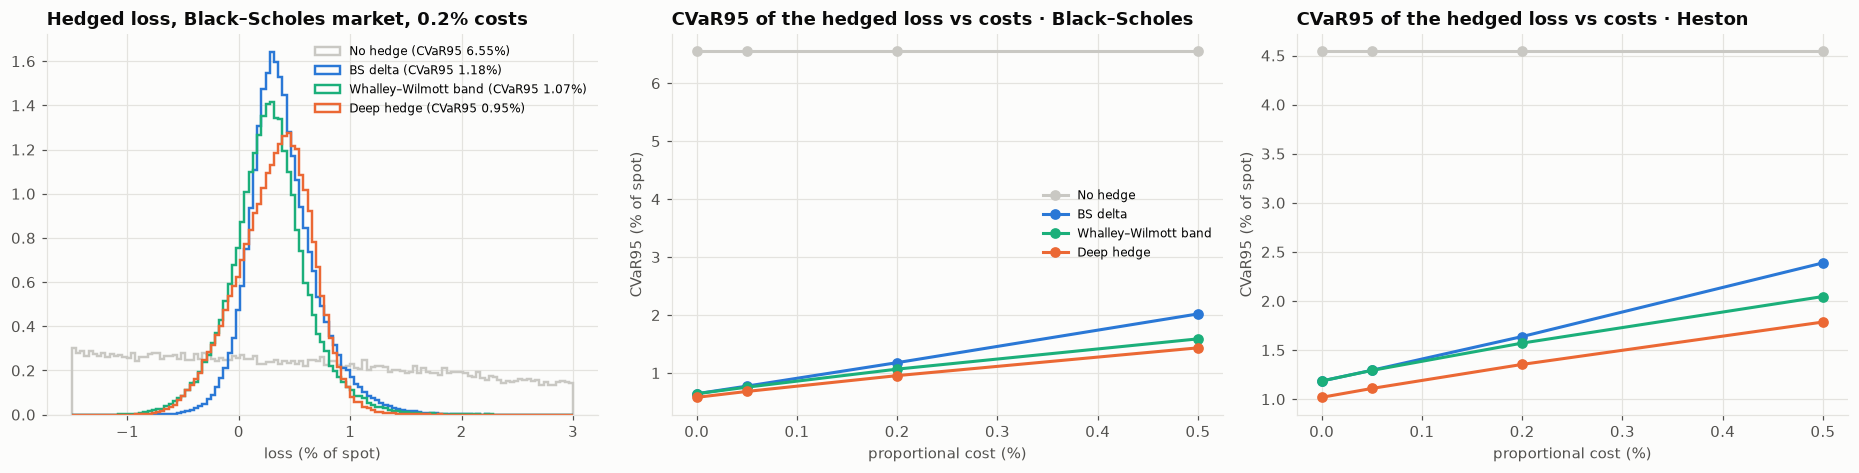

In [7]:
# --- Chart 1: loss distributions (BS model, 0.2% costs) and the risk-cost
# frontier
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
losses, policy, S_te, V_te = store[("Black–Scholes", 0.002)]
ax = axes[0]
bins = np.linspace(-1.5, 3.0, 120)
for strat, color in STRAT_COLORS.items():
    ax.hist(
        losses[strat][0] * 100,
        bins=bins,
        histtype="step",
        lw=1.6,
        color=color,
        density=True,
        label=f"{strat} (CVaR95 {cvar(losses[strat][0]) * 100:.2f}%)",
    )
ax.set_title("Hedged loss, Black–Scholes market, 0.2% costs")
ax.set_xlabel("loss (% of spot)")
ax.legend(fontsize=8)
for ax, model in zip(axes[1:], ("Black–Scholes", "Heston")):
    for strat, color in STRAT_COLORS.items():
        g = res[(res["model"] == model) & (res["strategy"] == strat)]
        ax.plot(
            g["cost"] * 100,
            g["CVaR95 (% spot)"],
            "o-",
            color=color,
            label=strat,
        )
    ax.set_title(f"CVaR95 of the hedged loss vs costs · {model}")
    ax.set_xlabel("proportional cost (%)")
    ax.set_ylabel("CVaR95 (% of spot)")
axes[1].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_loss_distribution_and_frontier")
plt.show()

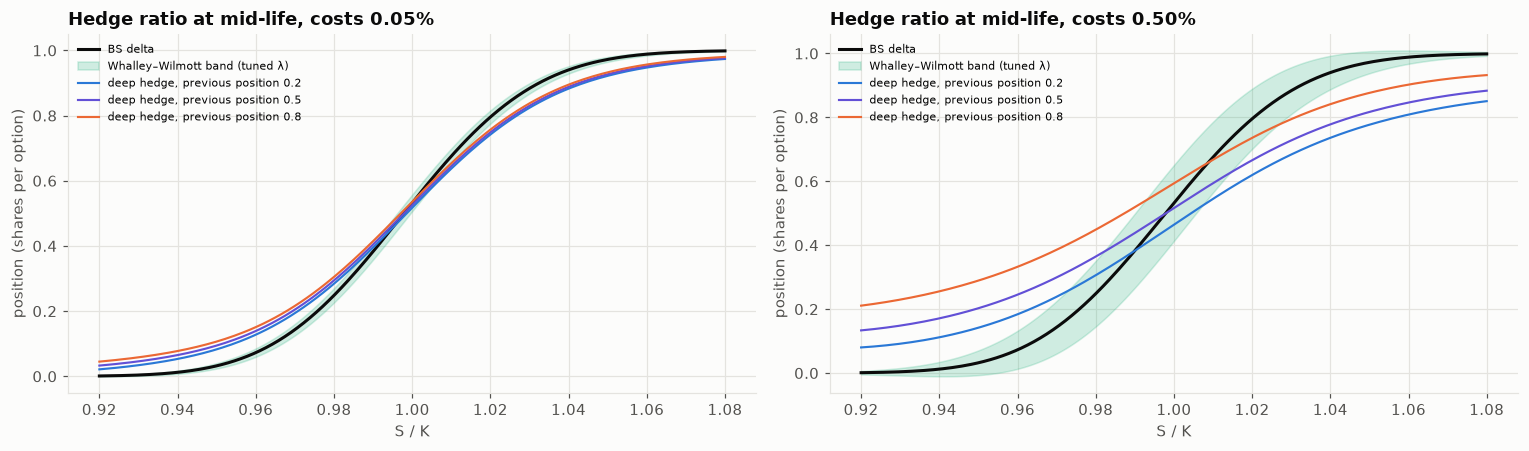

mean loss (% spot)  std (% spot)  \
model         strategy                                                 
Black–Scholes Deep hedge                          0.32          0.33   
              No hedge                            0.01          2.32   
              BS delta                            0.40          0.31   
              Whalley–Wilmott band                0.28          0.34   
Heston        Deep hedge                          0.20          0.54   
              No hedge                           -0.05          1.81   
              BS delta                            0.34          0.54   
              Whalley–Wilmott band                0.22          0.56   

                                    CVaR95 (% spot)  CVaR99 (% spot)  \
model         strategy                                                 
Black–Scholes Deep hedge                       0.95             1.17   
              No hedge                         6.55             9.01   
              BS delta                         1.18             1.53   
              Whalley–Wilmott band             1.07             1.41   
Heston        Deep hedge                       1.35             1.81   
              No hedge                         4.54             6.39   
              BS delta                         1.64             2.18   
              Whalley–Wilmott band             1.57             2.08   

                                    turnover (×)  indifference price (% spot)  
model         strategy                                                         
Black–Scholes Deep hedge                    1.58                         2.59  
              No hedge                      0.00                         8.19  
              BS delta                      1.96                         2.82  
              Whalley–Wilmott band          1.35                         2.71  
Heston        Deep hedge                    1.27                         2.99  
              No hedge                      0.00                         6.18  
              BS delta                      1.92                         3.28  
              Whalley–Wilmott band          1.35                         3.21

In [8]:
# --- Chart 2: what the network learned: hedge ratio vs previous position (a
# no-trade band)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
mny = np.linspace(0.92, 1.08, 200)
t_mid = N_DAYS // 2
tau = T - t_mid * DT
for ax, cost in zip(axes, (0.0005, 0.005)):
    _, pol, _, _ = store[("Black–Scholes", cost)]
    d_bs, g_bs = bs_delta_gamma(mny, K_REL, tau, SIGMA, R)
    ax.plot(mny, d_bs, color=INK, lw=2, label="BS delta")
    H = (
        1.5
        * np.exp(-R * tau)
        * cost
        * mny
        * g_bs**2
        / WW_LAMBDA[("Black–Scholes", cost)]
    ) ** (1 / 3)
    ax.fill_between(
        mny,
        d_bs - H,
        d_bs + H,
        color=PALETTE[2],
        alpha=0.2,
        label="Whalley–Wilmott band (tuned λ)",
    )
    for prev, color in [
        (0.2, PALETTE[0]),
        (0.5, PALETTE[6]),
        (0.8, PALETTE[1]),
    ]:
        x = torch.tensor(
            np.column_stack([
                np.log(mny / K_REL) / (SIGMA * np.sqrt(T)),
                np.full_like(mny, tau / T),
                np.full_like(mny, prev),
                d_bs,
            ]),
            dtype=torch.float32,
        )
        with torch.no_grad():
            ax.plot(
                mny,
                d_bs + pol(x).numpy(),
                color=color,
                lw=1.4,
                label=f"deep hedge, previous position {prev}",
            )
    ax.set_title(f"Hedge ratio at mid-life, costs {cost:.2%}")
    ax.set_xlabel("S / K")
    ax.set_ylabel("position (shares per option)")
    ax.legend(fontsize=7)
plt.tight_layout()
save_fig(fig, "02_learned_no_trade_band")
plt.show()
res.to_csv(OUT_DIR / "hedging_results.csv", index=False)
res[res["cost"] == 0.002].set_index(["model", "strategy"])[[
    "mean loss (% spot)",
    "std (% spot)",
    "CVaR95 (% spot)",
    "CVaR99 (% spot)",
    "turnover (×)",
    "indifference price (% spot)",
]].round(3)

## 7. Reading the results and limitations

Short one-month ATM SPY call (premium 1.64% of spot), 100,000 out-of-sample paths per case:

**The deep hedge has the lowest tail risk in every case.** Under Black–Scholes dynamics its CVaR95 is 0.58% of spot with no costs, against 0.64% for the daily delta. With 20 bp costs it is 0.95% against 1.18% for delta and 1.07% for the tuned Whalley–Wilmott band.

With 50 bp it is 1.43% against 2.02% and 1.59%. The gap widens with costs, which is where a policy that knows its own position has something to exploit.

- **Even without costs the network beats delta (0.58% vs 0.64%).** That is not a contradiction: daily rebalancing is discrete, and Black–Scholes delta minimises variance in continuous time, not the 95% tail of a discretely hedged position. The network instead shapes the whole distribution to thin the right tail.
- **Under Heston dynamics everything is harder** (CVaR 1.0–1.8% instead of 0.6–1.4%) because volatility is random and a single instrument cannot hedge it. The ranking is unchanged and the deep hedge's edge over delta is about 0.2–0.6 points.
- **What the network learned** (Chart 2). At 5 bp costs it tracks the delta closely and barely depends on its previous position. At 50 bp it does two things a desk would recognise:
  - it **flattens the hedge ratio**, holding less than delta in the money and more out of the money, which is how Leland's (1985) cost-adjusted delta behaves (as if hedging at a higher volatility);
  - its new position **leans toward the one it already holds** (the 0.2, 0.5 and 0.8 curves separate), a soft, data-driven version of the no-trade band.
  It also trades less: turnover of 1.58 vs 1.96 for delta at 20 bp, with a lower mean loss (0.32% vs 0.40% of spot) and a similar standard deviation.

**Pricing.** The indifference price, the premium that makes the CVaR acceptable, is 2.59% of spot for the deep hedge at 20 bp, against 2.82% for delta and 2.71% for the band, on an option whose Black–Scholes value is 1.64%. A dealer using the better policy can quote about 0.2% of spot tighter for the same tail risk, which on a $100mm notional is $230k.

**Benchmark tuning matters.** With the risk aversion λ = 1 that is common in textbook examples, the Whalley–Wilmott band was so wide that it looked worse than delta. Once λ is tuned on separate paths for the same CVaR objective, the band beats delta at every positive cost.

A deep-hedging result is only as convincing as the effort put into its benchmarks. At 5 bp the best λ is the top of the grid (10,000), so the band is essentially closed and equals delta.

**Limitations**

- Simulated markets only: the network is as good as the simulator. Training on a market generator or on historical paths is the natural extension.
- One option and one hedging instrument. Hedging with options (vega) as well as the underlying is where deep hedging differs most from textbook rules.
- The Heston parameters are illustrative, matched only to realised variance, and the variance is assumed observable.
- CVaR₉₅ is one choice of risk measure. Entropic risk or mean–variance give different policies and prices.

## References

### Finance and regulation

- Black, F., & Scholes, M. (1973). The pricing of options and corporate liabilities. *Journal of Political Economy, 81*(3), 637–654. https://doi.org/10.1086/260062
- Whalley, A. E., & Wilmott, P. (1997). An asymptotic analysis of an optimal hedging model for option pricing with transaction costs. *Mathematical Finance, 7*(3), 307–324. https://doi.org/10.1111/1467-9965.00034
- Leland, H. E. (1985). Option pricing and replication with transactions costs. *The Journal of Finance, 40*(5), 1283–1301. https://doi.org/10.1111/j.1540-6261.1985.tb02383.x
- Heston, S. L. (1993). A closed-form solution for options with stochastic volatility with applications to bond and currency options. *The Review of Financial Studies, 6*(2), 327–343. https://doi.org/10.1093/rfs/6.2.327
- Rockafellar, R. T., & Uryasev, S. (2000). Optimization of conditional value-at-risk. *Journal of Risk, 2*(3), 21–41. https://doi.org/10.21314/JOR.2000.038

### Machine learning and deep learning

- Buehler, H., Gonon, L., Teichmann, J., & Wood, B. (2019). Deep hedging. *Quantitative Finance, 19*(8), 1271–1291. https://doi.org/10.1080/14697688.2019.1571683
- Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., … Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems, 32*. https://arxiv.org/abs/1912.01703
- Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8), 1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735